In [ ]:
import numpy as np
#import xgboost as xgb
#import scipy.stats as stats
import scipy.special as special
import openturns as ot
from matplotlib import pyplot as plt
from typing import Dict, List, Tuple
from xgboost import XGBRegressor


In [2]:
import sys
import os

# Set project root relative to notebook location
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

In [3]:
from Losses import gaussian_xgb_loss as gauss
from Losses import clayton_xgb_loss as clayton
from Losses import gumbel_xgb_loss as gumbel

In [4]:
def partial_dependence_with_truth(
    model,
    X,
    feature_index,
    true_theta_fn=None,
    transform=None,
    grid=None,
    grid_resolution=50
):
    X = np.asarray(X)
    
    # Grid
    if grid is None:
        xj = X[:, feature_index]
        grid = np.linspace(xj.min(), xj.max(), grid_resolution)
    
    pdp = np.zeros_like(grid)
    truth = np.zeros_like(grid) if true_theta_fn else None
    
    for i, val in enumerate(grid):
        X_temp = X.copy()
        X_temp[:, feature_index] = val
        
        # Model PDP
        preds = model.predict(X_temp)
        if transform:
            preds = transform(preds)
        pdp[i] = preds.mean()
        
        # True PDP
        if true_theta_fn:
            theta_true = true_theta_fn(X_temp)
            #if transform:
                #theta_true = transform(theta_true)
            truth[i] = theta_true.mean()
    
    return grid, pdp, truth

def plot_pdp_with_truth(grid, pdp, truth=None, feature_name=None):
    plt.figure()
    
    plt.plot(grid, pdp, label="Model PDP", linewidth=2)
    
    if truth is not None:
        plt.plot(grid, truth, linestyle="--", label="True PDP", linewidth=2)
    
    plt.xlabel(feature_name if feature_name else "Feature")
    plt.ylabel("Effect on theta")
    plt.title("Partial Dependence Plot")
    plt.legend()
    plt.show()

In [ ]:
def sample_clayton_copula(theta_array, seed):
    """
    Sample one point from a bivariate Clayton copula for each parameter value in theta_array.
    
    Parameters:
        theta_array (np.ndarray): 1D array of positive Clayton copula parameters (theta > 0).
    
    Returns:
        samples (np.ndarray): Array of shape (n, 2) where each row is a sample (u1, u2).
    """
    ot.RandomGenerator.SetSeed(seed)
    samples = []
    for theta in theta_array:
        copula = ot.ClaytonCopula(theta)
        sample = copula.getSample(1)
        samples.append(sample[0])

    samples = np.array(samples)
    eps = 1e-10
    samples = np.clip(samples, eps, 1 - eps)
    return samples

def sample_gumbel_copula(theta_array, seed):
    """
    Sample one observation from a bivariate Gumbel copula for each theta.
    Uses OpenTURNS for sampling.
    
    Parameters:
        theta_array (np.ndarray): array of Gumbel copula parameters (theta >= 1)
    
    Returns:
        np.ndarray: shape (n, 2), copula samples in (0, 1)
    """
    ot.RandomGenerator.SetSeed(seed)
    samples = []
    for theta in theta_array:
        copula = ot.GumbelCopula(theta)
        sample = copula.getSample(1)
        samples.append(sample[0])
    
    samples = np.array(samples)
    # Clip to avoid 0 or 1
    eps = 1e-10
    samples = np.clip(samples, eps, 1 - eps)
    return samples


In [5]:
gauss_model = XGBRegressor(
    objective=gauss.gaussian_copula_nll_obj,
    n_estimators=500,
    tree_method="hist",
    eval_metric=gauss.gaussian_copula_nll_metric,
    early_stopping_rounds=3,
    learning_rate=0.01,
    max_depth=3,
    gamma=0.1,
    subsample=1.0,
    colsample_bytree=1.0,
    importance_type="total_gain"
)

In [12]:
# shape of generated data.
n = 6000
p = 10

ratio = 0.75
seed = 1

num_boost_round = 500

np.random.seed(seed=seed)

x = np.random.uniform(0, 1, (n, p))
#x = np.random.randn(kRows, kCols)
x1 = x[:, 0]
x2 = x[:, 1]
x3 = x[:, 2]

#theta = np.exp(0.01 - 0.2*(x1 < 0.3) + 0.2*np.sin(2*np.pi*x2) + x3**2 - x3*(np.abs(x2) > 0.5))

# First linear scenario
def true_tau1(X):
    x1 = X[:, 0]
    x2 = X[:, 1]
    x3 = X[:, 2]

    return special.expit(0.5 - 0.3 * x1 + 0.4*x2 - 2*x3)

tau1 = true_tau1(x)
# Second non-linear scenario
def true_tau2(X):
    x1 = X[:, 0]
    x2 = X[:, 1]
    x3 = X[:, 2]

    return special.expit(0.1 - 0.2*(x1 < 0.3) + 0.3*np.sin(2*np.pi*x2) + 0.5*x3**2 - 2.5*x3*(np.abs(x2) > 0.5))

tau2 = true_tau2(x)

#print(np.min(tau1))
#print(np.max(tau1))
    
#depA = (x1 < 0.4) & (x2 < 0.75)
#depB = (x1 >= 0.4) & (x2 < 0.75)
#depC = (x1 < 0.4) & (x2 >= 0.75)
#depD = (x1 >= 0.4) & (x2 >= 0.75)

#tau = np.zeros(n)
#tau[depA] = 0.1
#tau[depB] = 0.3
#tau[depC] = 0.5
#tau[depD] = 0.7

In [7]:
from sklearn.model_selection import train_test_split

y_gauss1 = gauss.sample_gaussian_copula(gauss.gauss_tau2par(tau1), seed=0)

#train, validation and test data split (70,10,20)
x_main_gauss1, x_test_gauss1, y_main_gauss1, y_test_gauss1 = train_test_split(x, y_gauss1, test_size=0.2, random_state=42)
x_train_gauss1, x_val_gauss1, y_train_gauss1, y_val_gauss1 = train_test_split(x_main_gauss1, y_main_gauss1, test_size=0.125, random_state=42)

y_gauss2 = gauss.sample_gaussian_copula(gauss.gauss_tau2par(tau2), seed=0)

#train, validation and test data split (70,10,20)
x_main_gauss2, x_test_gauss2, y_main_gauss2, y_test_gauss2 = train_test_split(x, y_gauss2, test_size=0.2, random_state=42)
x_train_gauss2, x_val_gauss2, y_train_gauss2, y_val_gauss2 = train_test_split(x_main_gauss2, y_main_gauss2, test_size=0.125, random_state=42)

In [8]:
gauss1_xgb = gauss_model.fit(x_train_gauss1, y_train_gauss1, eval_set=[(x_val_gauss1, y_val_gauss1)])

[0]	validation_0-rmse:0.29381	validation_0-gaussian_copula_nll_metric:-173.79716
[1]	validation_0-rmse:0.29449	validation_0-gaussian_copula_nll_metric:-175.95022
[2]	validation_0-rmse:0.29544	validation_0-gaussian_copula_nll_metric:-178.09066
[3]	validation_0-rmse:0.29668	validation_0-gaussian_copula_nll_metric:-180.21775
[4]	validation_0-rmse:0.29820	validation_0-gaussian_copula_nll_metric:-182.33070
[5]	validation_0-rmse:0.30002	validation_0-gaussian_copula_nll_metric:-184.42868
[6]	validation_0-rmse:0.30204	validation_0-gaussian_copula_nll_metric:-186.51841
[7]	validation_0-rmse:0.30433	validation_0-gaussian_copula_nll_metric:-188.60800
[8]	validation_0-rmse:0.30694	validation_0-gaussian_copula_nll_metric:-190.70225
[9]	validation_0-rmse:0.30980	validation_0-gaussian_copula_nll_metric:-192.76126
[10]	validation_0-rmse:0.31292	validation_0-gaussian_copula_nll_metric:-194.77133
[11]	validation_0-rmse:0.31629	validation_0-gaussian_copula_nll_metric:-196.77312
[12]	validation_0-rmse:0.3

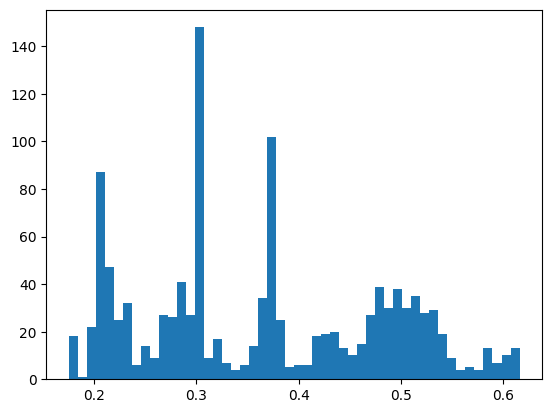

In [9]:
test_preds_gauss1 = gauss1_xgb.predict(x_test_gauss1)[:,0].reshape(-1,1)

plt.hist(gauss.gauss_par2tau(gauss.gaussian_inv_link(test_preds_gauss1)), bins=50)
plt.show()

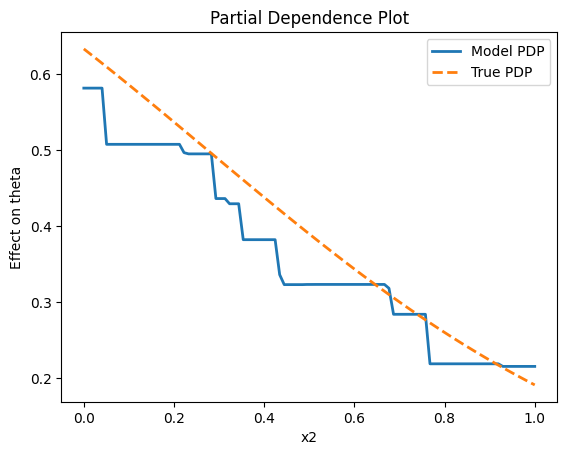

In [15]:
#def true_theta_fn(X):
    #x1, x2, x3 = X[:,0], X[:,1], X[:,2]
    #return special.expit(0.5 - 0.3 * x1 + 0.4*x2 - 2*x3)

#def transform(tpred):
    #return gauss.gauss_par2tau(gauss.gaussian_inv_link(tpred))

x_pdp = np.random.uniform(0, 1, (5000, 10))

grid, pdp, truth = partial_dependence_with_truth(
    gauss1_xgb,
    x_pdp,
    feature_index=2,
    true_theta_fn=true_tau1,
    transform=gauss.gauss_predt2tau,
    #grid_resolution=200,
    grid = np.linspace(0,1,100)
)

#print(truth)
#print(special.expit(1+0.5))
plot_pdp_with_truth(grid, pdp, truth, "x2")

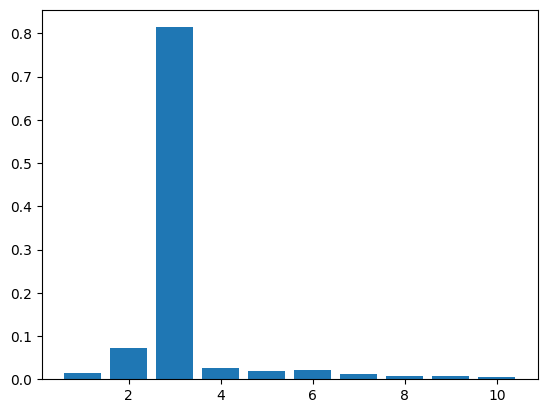

In [16]:
plt.bar(np.arange(1,11,1), gauss1_xgb.feature_importances_)
plt.show()

In [29]:
a = np.zeros((2,3))
a[0, :] = np.array([1, 2, 3])
print(a)

[[1. 2. 3.]
 [0. 0. 0.]]


In [17]:
u1 = gauss.sample_gaussian_copula(gauss.gauss_tau2par(tau1), seed)
print(u1)
print(np.array([[0.5,0.9]]))

[[0.83238873 0.90566398]
 [0.04814148 0.15070036]
 [0.13876182 0.4102914 ]
 ...
 [0.28150081 0.49349422]
 [0.362238   0.59610919]
 [0.69735753 0.44457722]]
[[0.5 0.9]]


In [25]:
import skfolio.distribution as skfd

def gaussian_deviance(y, rho_pred):
    gaussian_cop = gauss.GaussianCopula(itau=False)
    rho = []
    for u in y:
    #gaussian_cop = skfd.GaussianCopula(itau=False)
        gaussian_cop.fit(u.reshape(-1,2))
        rho.append(gaussian_cop.rho_)
        
    rho = np.array(rho).reshape(-1,1)
    return 2*(gauss.gaussian_lpdf(y, rho)- gauss.gaussian_lpdf(y, rho_pred))


print(gaussian_deviance(y_test_gauss1, gauss.gaussian_inv_link(test_preds_gauss1)))

gumbel_cop = skfd.GumbelCopula(itau=False)
gumbel_cop.fit(np.array([[0.4, 0.5]]))
#print(gumbel_cop.theta_)

clayton_cop = skfd.ClaytonCopula(itau=False)
clayton_cop.fit(np.array([[0.4, 0.5]]))
#print(clayton_cop.theta_)

gaussian_cop = skfd.GaussianCopula(itau=False)
gaussian_cop.fit(y_test_gauss1)
print(gaussian_cop.score(y_test_gauss1))

#gaussian_cop.fit(u1)
#print(gaussian_cop.rho_)

#print(gaussian_cop.score(u1))

rho = []

for u in y_test_gauss1:
    gaussian_cop = skfd.GaussianCopula(itau=False)
    gaussian_cop.fit(u.reshape(-1,2))
    rho.append(gaussian_cop.rho_)

rho = np.array(rho).reshape(-1,1)
#print(rho)
print(gauss.gaussian_lpdf(y_test_gauss1, rho))
print(gauss.gaussian_lpdf(y_test_gauss1, gauss.gaussian_inv_link(test_preds_gauss1)))
#print(gaussian_cop.score(u1))
#print(gaussian_cop.score(y_test_gauss1))
#print(clayton_cop.score(u1))
#print(gumbel_cop.score(u1))

1948.9390493133078
224.13726948673494
1252.745185292642
278.275660635988


In [1]:
import numpy as np
import scipy.special as special
import openturns as ot
from matplotlib import pyplot as plt
from typing import Dict, List, Tuple
from xgboost import XGBRegressor
import sys
import os

# Set project root relative to notebook location
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from Losses import gaussian_xgb_loss as gauss
from Losses import clayton_xgb_loss as clayton
from Losses import gumbel_xgb_loss as gumbel

from sklearn.model_selection import train_test_split

def mse(y, y_pred):
    return np.sum((y-y_pred)**2)

def partial_dependence_with_truth(
    model,
    X,
    feature_index,
    true_theta_fn=None,
    transform=None,
    grid=None,
    grid_resolution=50
):
    X = np.asarray(X)
    
    # Grid
    if grid is None:
        xj = X[:, feature_index]
        grid = np.linspace(xj.min(), xj.max(), grid_resolution)
    
    pdp = np.zeros_like(grid)
    truth = np.zeros_like(grid) if true_theta_fn else None
    
    for i, val in enumerate(grid):
        X_temp = X.copy()
        X_temp[:, feature_index] = val
        
        # Model PDP
        preds = model.predict(X_temp)
        if transform:
            preds = transform(preds)
        pdp[i] = preds.mean()
        
        # True PDP
        if true_theta_fn:
            theta_true = true_theta_fn(X_temp)
            #if transform:
                #theta_true = transform(theta_true)
            truth[i] = theta_true.mean()
    
    return grid, pdp, truth

gauss_model = XGBRegressor(
    objective=gauss.gaussian_copula_nll_obj,
    n_estimators=500,
    tree_method="hist",
    eval_metric=gauss.gaussian_copula_nll_metric,
    early_stopping_rounds=3,
    learning_rate=0.01,
    reg_lambda=0.2,
    max_depth=2,
    subsample=1.0,
    colsample_bytree=1.0,
    importance_type="total_gain"
)

np.random.seed(seed=321)
x_pdp = np.random.uniform(0, 1, (5000, 10))

# shape of generated data.
n_obs = 2000
p = 10

#ratio = 0.75
#num_boost_round = 500

grid_resolution = 100

n_sim = 1

results = {
    "linear": {"gaussian": {"pdp" : {"x1" : np.zeros((n_sim, grid_resolution)),
                        "x2" : np.zeros((n_sim, grid_resolution)),
                        "x3" : np.zeros((n_sim, grid_resolution))
                        }, 
               "feature_importance" : np.zeros((n_sim, p)), 
               "nll_xgb" : np.zeros((n_sim, 1)), 
               "nll_constant": np.zeros((n_sim, 1)),
               "mse_xgb":np.zeros((n_sim, 1)),
               "mse_constant":np.zeros((n_sim, 1))
               },
               "clayton": {"pdp" : {"x1" : np.zeros((n_sim, grid_resolution)),
                        "x2" : np.zeros((n_sim, grid_resolution)),
                        "x3" : np.zeros((n_sim, grid_resolution))
                        }, 
               "feature_importance" : np.zeros((n_sim, p)), 
               "nll_xgb" : np.zeros((n_sim, 1)), 
               "nll_constant": np.zeros((n_sim, 1)),
               "mse_xgb":np.zeros((n_sim, 1)),
               "mse_constant":np.zeros((n_sim, 1))
               },
               "gumbel": {"pdp" : {"x1" : np.zeros((n_sim, grid_resolution)),
                        "x2" : np.zeros((n_sim, grid_resolution)),
                        "x3" : np.zeros((n_sim, grid_resolution))
                        }, 
               "feature_importance" : np.zeros((n_sim, p)), 
               "nll_xgb" : np.zeros((n_sim, 1)), 
               "nll_constant": np.zeros((n_sim, 1)),
               "mse_xgb":np.zeros((n_sim, 1)),
               "mse_constant":np.zeros((n_sim, 1))
               }
               },
    "non-linear": {"gaussian":{"pdp" : {"x1" : np.zeros((n_sim, grid_resolution)),
                            "x2" : np.zeros((n_sim, grid_resolution)),
                            "x3" : np.zeros((n_sim, grid_resolution))
                            }, 
               "feature_importance" : np.zeros((n_sim, p)), 
               "nll_xgb" : np.zeros((n_sim, 1)), 
               "nll_constant": np.zeros((n_sim, 1)),
               "mse_xgb":np.zeros((n_sim, 1)),
               "mse_constant":np.zeros((n_sim, 1))
               },
               "clayton":{"pdp" : {"x1" : np.zeros((n_sim, grid_resolution)),
                        "x2" : np.zeros((n_sim, grid_resolution)),
                        "x3" : np.zeros((n_sim, grid_resolution))
                        }, 
               "feature_importance" : np.zeros((n_sim, p)), 
               "nll_xgb" : np.zeros((n_sim, 1)), 
               "nll_constant": np.zeros((n_sim, 1)),
               "mse_xgb":np.zeros((n_sim, 1)),
               "mse_constant":np.zeros((n_sim, 1))
               },
               "gumbel":{"pdp" : {"x1" : np.zeros((n_sim, grid_resolution)),
                        "x2" : np.zeros((n_sim, grid_resolution)),
                        "x3" : np.zeros((n_sim, grid_resolution))
                        }, 
               "feature_importance" : np.zeros((n_sim, p)), 
               "nll_xgb" : np.zeros((n_sim, 1)), 
               "nll_constant": np.zeros((n_sim, 1)),
               "mse_xgb":np.zeros((n_sim, 1)),
               "mse_constant":np.zeros((n_sim, 1))
               }
               }
}

for i in range(n_sim):
    
    seed = i+1
    np.random.seed(seed=seed)

    x = np.random.uniform(0, 1, (n_obs, p))
    
    x1 = x[:, 0]
    x2 = x[:, 1]
    x3 = x[:, 2]
    
    # First linear scenario
    def true_tau1(X):
        x1 = X[:, 0]
        x2 = X[:, 1]
        x3 = X[:, 2]

        return special.expit(0.5 - 0.3*x1 + 0.4*x2 - 2*x3)

    tau1 = true_tau1(x)

    # Second non-linear scenario
    def true_tau2(X):
        x1 = X[:, 0]
        x2 = X[:, 1]
        x3 = X[:, 2]

        return special.expit(0.1 - 0.2*(x1 < 0.3) + 0.3*np.sin(2*np.pi*x2) + 0.5*x3**2 - 2.5*x3*(x2 > 0.5))

    tau2 = true_tau2(x)

    y_gauss1 = gauss.sample_gaussian_copula(gauss.gauss_tau2par(tau1), seed=seed)

    #train, validation and test data split (70,10,20)
    x_main_gauss1, x_test_gauss1, y_main_gauss1, y_test_gauss1 = train_test_split(x, y_gauss1, test_size=0.2, random_state=42)
    x_train_gauss1, x_val_gauss1, y_train_gauss1, y_val_gauss1 = train_test_split(x_main_gauss1, y_main_gauss1, test_size=0.125, random_state=42)

    y_gauss2 = gauss.sample_gaussian_copula(gauss.gauss_tau2par(tau2), seed=seed)

    #train, validation and test data split (70,10,20)
    x_main_gauss2, x_test_gauss2, y_main_gauss2, y_test_gauss2 = train_test_split(x, y_gauss2, test_size=0.2, random_state=42)
    x_train_gauss2, x_val_gauss2, y_train_gauss2, y_val_gauss2 = train_test_split(x_main_gauss2, y_main_gauss2, test_size=0.125, random_state=42)

    # Fitting gaussian copula to linear scenario
    #gauss_model.set_params(reg_lambda=0.2, max_depth=2, base_score=gauss.get_initial_guess(y_train_gauss1))
    gauss1_xgb = gauss_model.fit(x_train_gauss1, y_train_gauss1, eval_set=[(x_val_gauss1, y_val_gauss1)])

    test_preds_gauss1 = gauss1_xgb.predict(x_test_gauss1)[:,0].reshape(-1,1)

    _, pdp_gauss1_x1, truth_linear_x1 = partial_dependence_with_truth(
        gauss1_xgb,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_tau1,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    _, pdp_gauss1_x2, truth_linear_x2 = partial_dependence_with_truth(
        gauss1_xgb,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_tau1,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    _, pdp_gauss1_x3, truth_linear_x3 = partial_dependence_with_truth(
        gauss1_xgb,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_tau1,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    results["linear"]["gaussian"]["pdp"]["x1"][i, :] = pdp_gauss1_x1
    results["linear"]["gaussian"]["pdp"]["x2"][i, :] = pdp_gauss1_x2
    results["linear"]["gaussian"]["pdp"]["x3"][i, :] = pdp_gauss1_x3

    results["linear"]["gaussian"]["feature_importance"][i, :] = gauss1_xgb.feature_importances_

    results["linear"]["gaussian"]["nll_xgb"][i] = gauss.gaussian_copula_nll_metric(y_test_gauss1, test_preds_gauss1)
    results["linear"]["gaussian"]["nll_constant"][i] = gauss.gaussian_copula_nll_metric(y_test_gauss1, gauss.get_initial_guess(y_test_gauss1))
    results["linear"]["gaussian"]["mse_xgb"][i] = mse(true_tau1(x_test_gauss1).reshape(-1,1), gauss.gauss_predt2tau(test_preds_gauss1))
    results["linear"]["gaussian"]["mse_constant"][i] = mse(true_tau1(x_test_gauss1), gauss.gaussian_inv_link(gauss.get_initial_guess(y_test_gauss1)))


    # Fitting gaussian copula to non-linear scenario
    #gauss_model.set_params(reg_lambda=0.2, max_depth=2, base_score=gauss.get_initial_guess(y_train_gauss2))
    gauss2_xgb = gauss_model.fit(x_train_gauss2, y_train_gauss2, eval_set=[(x_val_gauss2, y_val_gauss2)])

    test_preds_gauss2 = gauss2_xgb.predict(x_test_gauss2)[:,0].reshape(-1,1)

    _, pdp_gauss2_x1, truth_nonlinear_x1 = partial_dependence_with_truth(
        gauss2_xgb,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_tau2,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    _, pdp_gauss2_x2, truth_nonlinear_x2 = partial_dependence_with_truth(
        gauss2_xgb,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_tau2,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    _, pdp_gauss2_x3, truth_nonlinear_x3 = partial_dependence_with_truth(
        gauss2_xgb,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_tau2,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    results["non-linear"]["gaussian"]["pdp"]["x1"][i, :] = pdp_gauss2_x1
    results["non-linear"]["gaussian"]["pdp"]["x2"][i, :] = pdp_gauss2_x2
    results["non-linear"]["gaussian"]["pdp"]["x3"][i, :] = pdp_gauss2_x3

    results["non-linear"]["gaussian"]["feature_importance"][i, :] = gauss2_xgb.feature_importances_

    results["non-linear"]["gaussian"]["nll_xgb"][i] = gauss.gaussian_copula_nll_metric(y_test_gauss2, test_preds_gauss2)
    results["non-linear"]["gaussian"]["nll_constant"][i] = gauss.gaussian_copula_nll_metric(y_test_gauss2, gauss.get_initial_guess(y_test_gauss2))
    results["non-linear"]["gaussian"]["mse_xgb"][i] = mse(true_tau2(x_test_gauss2).reshape(-1,1), gauss.gauss_predt2tau(test_preds_gauss2))
    results["non-linear"]["gaussian"]["mse_constant"][i] = mse(true_tau2(x_test_gauss2), gauss.gaussian_inv_link(gauss.get_initial_guess(y_test_gauss2)))

[0]	validation_0-rmse:0.28606	validation_0-gaussian_copula_nll_metric:-50.25958
[1]	validation_0-rmse:0.28714	validation_0-gaussian_copula_nll_metric:-50.97495
[2]	validation_0-rmse:0.28852	validation_0-gaussian_copula_nll_metric:-51.68926
[3]	validation_0-rmse:0.29021	validation_0-gaussian_copula_nll_metric:-52.40232
[4]	validation_0-rmse:0.29221	validation_0-gaussian_copula_nll_metric:-53.11395
[5]	validation_0-rmse:0.29452	validation_0-gaussian_copula_nll_metric:-53.82390
[6]	validation_0-rmse:0.29715	validation_0-gaussian_copula_nll_metric:-54.53196
[7]	validation_0-rmse:0.30009	validation_0-gaussian_copula_nll_metric:-55.23790
[8]	validation_0-rmse:0.30335	validation_0-gaussian_copula_nll_metric:-55.94144
[9]	validation_0-rmse:0.30692	validation_0-gaussian_copula_nll_metric:-56.64233
[10]	validation_0-rmse:0.31074	validation_0-gaussian_copula_nll_metric:-57.36800
[11]	validation_0-rmse:0.31489	validation_0-gaussian_copula_nll_metric:-58.09082
[12]	validation_0-rmse:0.31935	validat

In [ ]:
import numpy as np
import scipy.special as special
import openturns as ot
from matplotlib import pyplot as plt
from typing import Dict, List, Tuple
from xgboost import XGBRegressor
import sys
import os

# Set project root relative to notebook location
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from Losses import gaussian_xgb_loss as gauss
from Losses import clayton_xgb_loss as clayton
from Losses import gumbel_xgb_loss as gumbel

from sklearn.model_selection import train_test_split

def mse(y, y_pred):
    return np.sum((y-y_pred)**2)

def partial_dependence_with_truth(
    model,
    X,
    feature_index,
    true_theta_fn=None,
    transform=None,
    grid=None,
    grid_resolution=50
):
    X = np.asarray(X)
    
    # Grid
    if grid is None:
        xj = X[:, feature_index]
        grid = np.linspace(xj.min(), xj.max(), grid_resolution)
    
    pdp = np.zeros_like(grid)
    truth = np.zeros_like(grid) if true_theta_fn else None
    
    for i, val in enumerate(grid):
        X_temp = X.copy()
        X_temp[:, feature_index] = val
        
        # Model PDP
        preds = model.predict(X_temp)
        if transform:
            preds = transform(preds)
        pdp[i] = preds.mean()
        
        # True PDP
        if true_theta_fn:
            theta_true = true_theta_fn(X_temp)
            #if transform:
                #theta_true = transform(theta_true)
            truth[i] = theta_true.mean()
    
    return grid, pdp.tolist(), truth

gauss_model = XGBRegressor(
    objective=gauss.gaussian_copula_nll_obj,
    n_estimators=500,
    tree_method="hist",
    eval_metric=gauss.gaussian_copula_nll_metric,
    early_stopping_rounds=3,
    learning_rate=0.01,
    reg_lambda=0.2,
    max_depth=2,
    subsample=1.0,
    colsample_bytree=1.0,
    importance_type="total_gain"
)

clayton_model = XGBRegressor(
    objective=clayton.clayton_copula_nll_obj,
    n_estimators=500,
    tree_method="hist",
    eval_metric=clayton.clayton_copula_nll_metric,
    early_stopping_rounds=3,
    learning_rate=0.01,
    reg_lambda=0.2,
    max_depth=1,
    subsample=1.0,
    colsample_bytree=1.0,
    importance_type="total_gain"
)

gumbel_model = XGBRegressor(
    objective=gumbel.gumbel_copula_nll_obj,
    n_estimators=500,
    tree_method="hist",
    eval_metric=gumbel.gumbel_copula_nll_metric,
    early_stopping_rounds=3,
    learning_rate=0.1,
    reg_lambda=0.1,
    max_depth=1,
    subsample=1.0,
    colsample_bytree=1.0,
    importance_type="total_gain"
)

np.random.seed(seed=321)
x_pdp = np.random.uniform(0, 1, (5000, 10))

# shape of generated data.
n_obs = 2000
p = 10

#ratio = 0.75
#num_boost_round = 500

grid_resolution = 100

n_sim = 2

results = {
    "linear": {"gaussian": {"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "nll_xgb" : [], 
               "nll_constant": [],
               "mse_xgb": [],
               "mse_constant": []
               },
               "clayton": {"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "nll_xgb" : [], 
               "nll_constant": [],
               "mse_xgb": [],
               "mse_constant": []
               },
               "gumbel": {"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "nll_xgb" : [], 
               "nll_constant": [],
               "mse_xgb": [],
               "mse_constant": []
               }
               },
    "non-linear": {"gaussian":{"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "nll_xgb" : [], 
               "nll_constant": [],
               "mse_xgb": [],
               "mse_constant": []
               },
               "clayton":{"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "nll_xgb" : [], 
               "nll_constant": [],
               "mse_xgb": [],
               "mse_constant": []
               },
               "gumbel":{"pdp" : {"x1" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x2" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)],
                        "x3" : [[None for _ in range(grid_resolution)] for _ in range(n_sim)]
                        }, 
               "feature_importance" : [[None for _ in range(p)] for _ in range(n_sim)], 
               "nll_xgb" : [], 
               "nll_constant": [],
               "mse_xgb": [],
               "mse_constant": []
               }
               }
}

for i in range(n_sim):
    
    seed = i+1
    np.random.seed(seed=seed)

    x = np.random.uniform(0, 1, (n_obs, p))
    
    x1 = x[:, 0]
    x2 = x[:, 1]
    x3 = x[:, 2]
    
    # First linear scenario
    def true_tau1(X):
        x1 = X[:, 0]
        x2 = X[:, 1]
        x3 = X[:, 2]

        return special.expit(0.5 - 0.3*x1 + 0.4*x2 - 2*x3)

    tau1 = true_tau1(x)

    # Second non-linear scenario
    def true_tau2(X):
        x1 = X[:, 0]
        x2 = X[:, 1]
        x3 = X[:, 2]

        return special.expit(0.1 - 0.2*(x1 < 0.3) + 0.3*np.sin(2*np.pi*x2) + 0.5*x3**2 - 2.5*x3*(x2 > 0.5))

    tau2 = true_tau2(x)

    # Gaussian copula

    y_gauss1 = gauss.sample_gaussian_copula(gauss.gauss_tau2par(tau1), seed=seed)

    #train, validation and test data split (70,10,20)
    x_main_gauss1, x_test_gauss1, y_main_gauss1, y_test_gauss1 = train_test_split(x, y_gauss1, test_size=0.2, random_state=42)
    x_train_gauss1, x_val_gauss1, y_train_gauss1, y_val_gauss1 = train_test_split(x_main_gauss1, y_main_gauss1, test_size=0.125, random_state=42)

    y_gauss2 = gauss.sample_gaussian_copula(gauss.gauss_tau2par(tau2), seed=seed)

    #train, validation and test data split (70,10,20)
    x_main_gauss2, x_test_gauss2, y_main_gauss2, y_test_gauss2 = train_test_split(x, y_gauss2, test_size=0.2, random_state=42)
    x_train_gauss2, x_val_gauss2, y_train_gauss2, y_val_gauss2 = train_test_split(x_main_gauss2, y_main_gauss2, test_size=0.125, random_state=42)

    # Fitting gaussian copula to linear scenario
    #gauss_model.set_params(reg_lambda=0.2, max_depth=2, base_score=gauss.get_initial_guess(y_train_gauss1))
    gauss1_xgb = gauss_model.fit(x_train_gauss1, y_train_gauss1, eval_set=[(x_val_gauss1, y_val_gauss1)])

    test_preds_gauss1 = gauss1_xgb.predict(x_test_gauss1)[:,0].reshape(-1,1)

    _, pdp_gauss1_x1, truth_linear_x1 = partial_dependence_with_truth(
        gauss1_xgb,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_tau1,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    _, pdp_gauss1_x2, truth_linear_x2 = partial_dependence_with_truth(
        gauss1_xgb,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_tau1,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    _, pdp_gauss1_x3, truth_linear_x3 = partial_dependence_with_truth(
        gauss1_xgb,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_tau1,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    results["linear"]["gaussian"]["pdp"]["x1"][i] = pdp_gauss1_x1
    results["linear"]["gaussian"]["pdp"]["x2"][i] = pdp_gauss1_x2
    results["linear"]["gaussian"]["pdp"]["x3"][i] = pdp_gauss1_x3

    results["linear"]["gaussian"]["feature_importance"][i] = gauss1_xgb.feature_importances_.tolist()

    results["linear"]["gaussian"]["nll_xgb"].append(gauss.gaussian_copula_nll_metric(y_test_gauss1, test_preds_gauss1))
    results["linear"]["gaussian"]["nll_constant"].append(gauss.gaussian_copula_nll_metric(y_test_gauss1, gauss.get_initial_guess(y_test_gauss1)))
    results["linear"]["gaussian"]["mse_xgb"].append(mse(true_tau1(x_test_gauss1).reshape(-1,1), gauss.gauss_predt2tau(test_preds_gauss1)))
    results["linear"]["gaussian"]["mse_constant"].append(mse(true_tau1(x_test_gauss1), gauss.gauss_predt2tau(gauss.get_initial_guess(y_test_gauss1))))


    # Fitting gaussian copula to non-linear scenario
    #gauss_model.set_params(reg_lambda=0.2, max_depth=2, base_score=gauss.get_initial_guess(y_train_gauss2))
    gauss2_xgb = gauss_model.fit(x_train_gauss2, y_train_gauss2, eval_set=[(x_val_gauss2, y_val_gauss2)])

    test_preds_gauss2 = gauss2_xgb.predict(x_test_gauss2)[:,0].reshape(-1,1)

    _, pdp_gauss2_x1, truth_nonlinear_x1 = partial_dependence_with_truth(
        gauss2_xgb,
        x_pdp,
        feature_index=0,
        true_theta_fn=true_tau2,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    _, pdp_gauss2_x2, truth_nonlinear_x2 = partial_dependence_with_truth(
        gauss2_xgb,
        x_pdp,
        feature_index=1,
        true_theta_fn=true_tau2,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    _, pdp_gauss2_x3, truth_nonlinear_x3 = partial_dependence_with_truth(
        gauss2_xgb,
        x_pdp,
        feature_index=2,
        true_theta_fn=true_tau2,
        transform=gauss.gauss_predt2tau,
        grid = np.linspace(0,1,grid_resolution)
    )

    results["non-linear"]["gaussian"]["pdp"]["x1"][i] = pdp_gauss2_x1
    results["non-linear"]["gaussian"]["pdp"]["x2"][i] = pdp_gauss2_x2
    results["non-linear"]["gaussian"]["pdp"]["x3"][i] = pdp_gauss2_x3

    results["non-linear"]["gaussian"]["feature_importance"][i] = gauss2_xgb.feature_importances_.tolist()

    results["non-linear"]["gaussian"]["nll_xgb"].append(gauss.gaussian_copula_nll_metric(y_test_gauss2, test_preds_gauss2))
    results["non-linear"]["gaussian"]["nll_constant"].append(gauss.gaussian_copula_nll_metric(y_test_gauss2, gauss.get_initial_guess(y_test_gauss2)))
    results["non-linear"]["gaussian"]["mse_xgb"].append(mse(true_tau2(x_test_gauss2).reshape(-1,1), gauss.gauss_predt2tau(test_preds_gauss2)))
    results["non-linear"]["gaussian"]["mse_constant"].append(mse(true_tau2(x_test_gauss2), gauss.gauss_predt2tau(gauss.get_initial_guess(y_test_gauss2))))




    #Clayton copula

    y_clayton1 = clayton.sample_clayton_copula(clayton.clayton_tau2par(tau1), seed=seed)

    #train, validation and test data split (70,10,20)
    x_main_clayton1, x_test_clayton1, y_main_clayton1, y_test_clayton1 = train_test_split(x, y_clayton1, test_size=0.2, random_state=42)
    x_train_clayton1, x_val_clayton1, y_train_clayton1, y_val_clayton1 = train_test_split(x_main_clayton1, y_main_clayton1, test_size=0.125, random_state=42)

    y_clayton2 = clayton.sample_clayton_copula(clayton.clayton_tau2par(tau2), seed=seed)

    #train, validation and test data split (70,10,20)
    x_main_clayton2, x_test_clayton2, y_main_clayton2, y_test_clayton2 = train_test_split(x, y_clayton2, test_size=0.2, random_state=42)
    x_train_clayton2, x_val_clayton2, y_train_clayton2, y_val_clayton2 = train_test_split(x_main_clayton2, y_main_clayton2, test_size=0.125, random_state=42)

    # Fitting clayton copula to linear scenario
    try:
        clayton1_xgb = clayton_model.fit(x_train_clayton1, y_train_clayton1, eval_set=[(x_val_clayton1, y_val_clayton1)])

        test_preds_clayton1 = clayton1_xgb.predict(x_test_clayton1)[:,0].reshape(-1,1)

        _, pdp_clayton1_x1, truth_linear_x1 = partial_dependence_with_truth(
            clayton1_xgb,
            x_pdp,
            feature_index=0,
            true_theta_fn=true_tau1,
            transform=clayton.clayton_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        _, pdp_clayton1_x2, truth_linear_x2 = partial_dependence_with_truth(
            clayton1_xgb,
            x_pdp,
            feature_index=1,
            true_theta_fn=true_tau1,
            transform=clayton.clayton_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        _, pdp_clayton1_x3, truth_linear_x3 = partial_dependence_with_truth(
            clayton1_xgb,
            x_pdp,
            feature_index=2,
            true_theta_fn=true_tau1,
            transform=clayton.clayton_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        results["linear"]["clayton"]["pdp"]["x1"][i] = pdp_clayton1_x1
        results["linear"]["clayton"]["pdp"]["x2"][i] = pdp_clayton1_x2
        results["linear"]["clayton"]["pdp"]["x3"][i] = pdp_clayton1_x3

        results["linear"]["clayton"]["feature_importance"][i] = clayton1_xgb.feature_importances_.tolist()

        results["linear"]["clayton"]["nll_xgb"].append(clayton.clayton_copula_nll_metric(y_test_clayton1, test_preds_clayton1))
        results["linear"]["clayton"]["nll_constant"].append(clayton.clayton_copula_nll_metric(y_test_clayton1, clayton.get_initial_guess(y_test_clayton1)))
        results["linear"]["clayton"]["mse_xgb"].append(mse(true_tau1(x_test_clayton1).reshape(-1,1), clayton.clayton_predt2tau(test_preds_clayton1)))
        results["linear"]["clayton"]["mse_constant"].append(mse(true_tau1(x_test_clayton1), clayton.clayton_predt2tau(clayton.get_initial_guess(y_test_clayton1))))
    except:
        pass

    
    #print(clayton.get_initial_guess(y_test_clayton1))


    # Fitting clayton copula to non-linear scenario
    try:
        clayton2_xgb = clayton_model.fit(x_train_clayton2, y_train_clayton2, eval_set=[(x_val_clayton2, y_val_clayton2)])

        test_preds_clayton2 = clayton2_xgb.predict(x_test_clayton2)[:,0].reshape(-1,1)

        _, pdp_clayton2_x1, truth_nonlinear_x1 = partial_dependence_with_truth(
            clayton2_xgb,
            x_pdp,
            feature_index=0,
            true_theta_fn=true_tau2,
            transform=clayton.clayton_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        _, pdp_clayton2_x2, truth_nonlinear_x2 = partial_dependence_with_truth(
            clayton2_xgb,
            x_pdp,
            feature_index=1,
            true_theta_fn=true_tau2,
            transform=clayton.clayton_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        _, pdp_clayton2_x3, truth_nonlinear_x3 = partial_dependence_with_truth(
            clayton2_xgb,
            x_pdp,
            feature_index=2,
            true_theta_fn=true_tau2,
            transform=clayton.clayton_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        results["non-linear"]["clayton"]["pdp"]["x1"][i] = pdp_clayton2_x1
        results["non-linear"]["clayton"]["pdp"]["x2"][i] = pdp_clayton2_x2
        results["non-linear"]["clayton"]["pdp"]["x3"][i] = pdp_clayton2_x3

        results["non-linear"]["clayton"]["feature_importance"][i] = clayton2_xgb.feature_importances_.tolist()

        results["non-linear"]["clayton"]["nll_xgb"].append(clayton.clayton_copula_nll_metric(y_test_clayton2, test_preds_clayton2))
        results["non-linear"]["clayton"]["nll_constant"].append(clayton.clayton_copula_nll_metric(y_test_clayton2, clayton.get_initial_guess(y_test_clayton2)))
        results["non-linear"]["clayton"]["mse_xgb"].append(mse(true_tau2(x_test_clayton2).reshape(-1,1), clayton.clayton_predt2tau(test_preds_clayton2)))
        results["non-linear"]["clayton"]["mse_constant"].append(mse(true_tau2(x_test_clayton2), clayton.clayton_predt2tau(clayton.get_initial_guess(y_test_clayton2))))
    except:
        pass


    # Gumbel copula

    y_gumbel1 = gumbel.sample_gumbel_copula(gumbel.gumbel_tau2par(tau1), seed=seed)

    #train, validation and test data split (70,10,20)
    x_main_gumbel1, x_test_gumbel1, y_main_gumbel1, y_test_gumbel1 = train_test_split(x, y_gumbel1, test_size=0.2, random_state=42)
    x_train_gumbel1, x_val_gumbel1, y_train_gumbel1, y_val_gumbel1 = train_test_split(x_main_gumbel1, y_main_gumbel1, test_size=0.125, random_state=42)

    y_gumbel2 = gumbel.sample_gumbel_copula(gumbel.gumbel_tau2par(tau2), seed=seed)

    #train, validation and test data split (70,10,20)
    x_main_gumbel2, x_test_gumbel2, y_main_gumbel2, y_test_gumbel2 = train_test_split(x, y_gumbel2, test_size=0.2, random_state=42)
    x_train_gumbel2, x_val_gumbel2, y_train_gumbel2, y_val_gumbel2 = train_test_split(x_main_gumbel2, y_main_gumbel2, test_size=0.125, random_state=42)

    # Fitting gumbel copula to linear scenario
    try:
        gumbel1_xgb = gumbel_model.fit(x_train_gumbel1, y_train_gumbel1, eval_set=[(x_val_gumbel1, y_val_gumbel1)])

        test_preds_gumbel1 = gumbel1_xgb.predict(x_test_gumbel1)[:,0].reshape(-1,1)

        _, pdp_gumbel1_x1, truth_linear_x1 = partial_dependence_with_truth(
            gumbel1_xgb,
            x_pdp,
            feature_index=0,
            true_theta_fn=true_tau1,
            transform=gumbel.gumbel_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        _, pdp_gumbel1_x2, truth_linear_x2 = partial_dependence_with_truth(
            gumbel1_xgb,
            x_pdp,
            feature_index=1,
            true_theta_fn=true_tau1,
            transform=gumbel.gumbel_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        _, pdp_gumbel1_x3, truth_linear_x3 = partial_dependence_with_truth(
            gumbel1_xgb,
            x_pdp,
            feature_index=2,
            true_theta_fn=true_tau1,
            transform=gumbel.gumbel_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        results["linear"]["gumbel"]["pdp"]["x1"][i] = pdp_gumbel1_x1
        results["linear"]["gumbel"]["pdp"]["x2"][i] = pdp_gumbel1_x2
        results["linear"]["gumbel"]["pdp"]["x3"][i] = pdp_gumbel1_x3

        results["linear"]["gumbel"]["feature_importance"][i] = gumbel1_xgb.feature_importances_.tolist()

        results["linear"]["gumbel"]["nll_xgb"].append(gumbel.gumbel_copula_nll_metric(y_test_gumbel1, test_preds_gumbel1))
        results["linear"]["gumbel"]["nll_constant"].append(gumbel.gumbel_copula_nll_metric(y_test_gumbel1, gumbel.get_initial_guess(y_test_gumbel1)))
        results["linear"]["gumbel"]["mse_xgb"].append(mse(true_tau1(x_test_gumbel1).reshape(-1,1), gumbel.gumbel_predt2tau(test_preds_gumbel1)))
        results["linear"]["gumbel"]["mse_constant"].append(mse(true_tau1(x_test_gumbel1), gumbel.gumbel_predt2tau(gumbel.get_initial_guess(y_test_gumbel1))))
    except:
        pass


    # Fitting gumbel copula to non-linear scenario
    try:
        gumbel2_xgb = gumbel_model.fit(x_train_gumbel2, y_train_gumbel2, eval_set=[(x_val_gumbel2, y_val_gumbel2)])

        test_preds_gumbel2 = gumbel2_xgb.predict(x_test_gumbel2)[:,0].reshape(-1,1)

        _, pdp_gumbel2_x1, truth_nonlinear_x1 = partial_dependence_with_truth(
            gumbel2_xgb,
            x_pdp,
            feature_index=0,
            true_theta_fn=true_tau2,
            transform=gumbel.gumbel_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        _, pdp_gumbel2_x2, truth_nonlinear_x2 = partial_dependence_with_truth(
            gumbel2_xgb,
            x_pdp,
            feature_index=1,
            true_theta_fn=true_tau2,
            transform=gumbel.gumbel_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        _, pdp_gumbel2_x3, truth_nonlinear_x3 = partial_dependence_with_truth(
            gumbel2_xgb,
            x_pdp,
            feature_index=2,
            true_theta_fn=true_tau2,
            transform=gumbel.gumbel_predt2tau,
            grid = np.linspace(0,1,grid_resolution)
        )

        results["non-linear"]["gumbel"]["pdp"]["x1"][i] = pdp_gumbel2_x1
        results["non-linear"]["gumbel"]["pdp"]["x2"][i] = pdp_gumbel2_x2
        results["non-linear"]["gumbel"]["pdp"]["x3"][i] = pdp_gumbel2_x3

        results["non-linear"]["gumbel"]["feature_importance"][i] = gumbel2_xgb.feature_importances_.tolist()

        results["non-linear"]["gumbel"]["nll_xgb"].append(gumbel.gumbel_copula_nll_metric(y_test_gumbel2, test_preds_gumbel2))
        results["non-linear"]["gumbel"]["nll_constant"].append(gumbel.gumbel_copula_nll_metric(y_test_gumbel2, gumbel.get_initial_guess(y_test_gumbel2)))
        results["non-linear"]["gumbel"]["mse_xgb"].append(mse(true_tau2(x_test_gumbel2).reshape(-1,1), gumbel.gumbel_predt2tau(test_preds_gumbel2)))
        results["non-linear"]["gumbel"]["mse_constant"].append(mse(true_tau2(x_test_gumbel2), gumbel.gumbel_predt2tau(gumbel.get_initial_guess(y_test_gumbel2))))
    except:
        pass

[0]	validation_0-rmse:0.28606	validation_0-gaussian_copula_nll_metric:-50.25958
[1]	validation_0-rmse:0.28714	validation_0-gaussian_copula_nll_metric:-50.97495
[2]	validation_0-rmse:0.28852	validation_0-gaussian_copula_nll_metric:-51.68926
[3]	validation_0-rmse:0.29021	validation_0-gaussian_copula_nll_metric:-52.40232
[4]	validation_0-rmse:0.29221	validation_0-gaussian_copula_nll_metric:-53.11395
[5]	validation_0-rmse:0.29452	validation_0-gaussian_copula_nll_metric:-53.82390
[6]	validation_0-rmse:0.29715	validation_0-gaussian_copula_nll_metric:-54.53196
[7]	validation_0-rmse:0.30009	validation_0-gaussian_copula_nll_metric:-55.23790
[8]	validation_0-rmse:0.30335	validation_0-gaussian_copula_nll_metric:-55.94144
[9]	validation_0-rmse:0.30692	validation_0-gaussian_copula_nll_metric:-56.64233
[10]	validation_0-rmse:0.31074	validation_0-gaussian_copula_nll_metric:-57.36800
[11]	validation_0-rmse:0.31489	validation_0-gaussian_copula_nll_metric:-58.09082
[12]	validation_0-rmse:0.31935	validat

In [2]:
import json
# write to json file
with open('phase1_results.json', 'w', encoding='utf-8') as f:
    json.dump(results, f, ensure_ascii=False, indent=4)

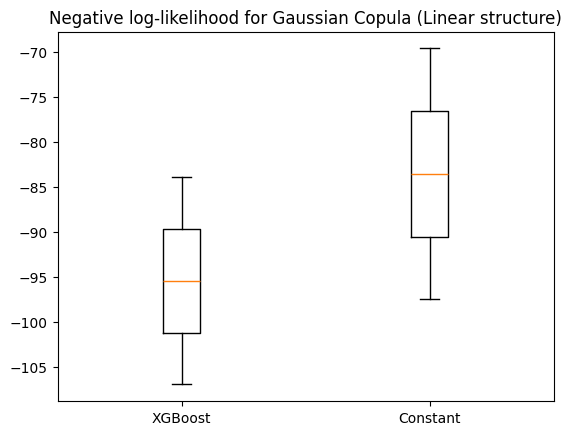

In [22]:
plt.boxplot([results["linear"]["gaussian"]["nll_xgb"], results["linear"]["gaussian"]["nll_constant"]], tick_labels=["XGBoost", "Constant"])
plt.title("Negative log-likelihood for Gaussian Copula (Linear structure)")
plt.show()

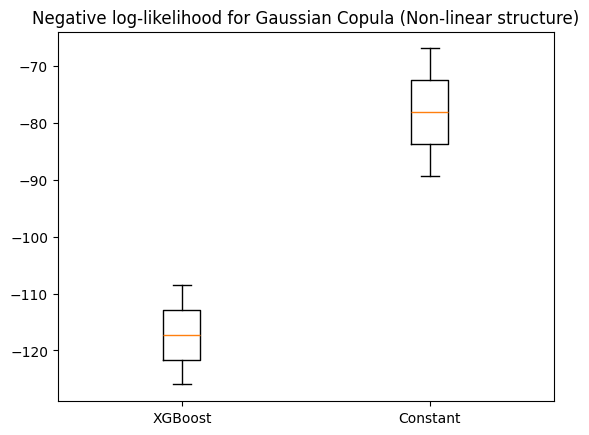

In [23]:
plt.boxplot([results["non-linear"]["gaussian"]["nll_xgb"], results["non-linear"]["gaussian"]["nll_constant"]], tick_labels=["XGBoost", "Constant"])
plt.title("Negative log-likelihood for Gaussian Copula (Non-linear structure)")
plt.show()

10


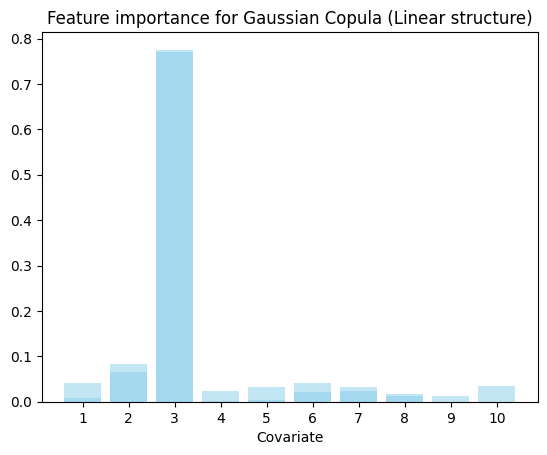

In [33]:
print(len(results["linear"]["gaussian"]["feature_importance"][0]))
for i in range(n_sim):
    plt.bar(np.arange(1,11,1), results["linear"]["gaussian"]["feature_importance"][i], alpha=0.5, color="skyblue")
    #plt.bar(np.arange(1,11,1), results["linear"]["gaussian"]["feature_importance"][1], alpha=0.5)
plt.title("Feature importance for Gaussian Copula (Linear structure)")
plt.xticks([1,2,3,4,5,6,7,8,9,10])
plt.xlabel("Covariate")
plt.show()

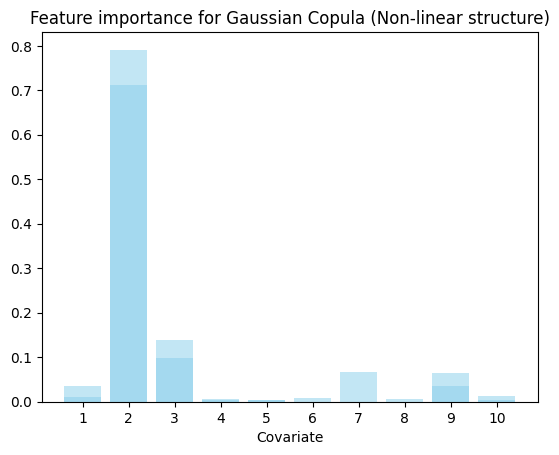

In [34]:
for i in range(n_sim):
    plt.bar(np.arange(1,11,1), results["non-linear"]["gaussian"]["feature_importance"][i], alpha=0.5, color="skyblue")
    #plt.bar(np.arange(1,11,1), results["linear"]["gaussian"]["feature_importance"][1], alpha=0.5)
plt.title("Feature importance for Gaussian Copula (Non-linear structure)")
plt.xticks([1,2,3,4,5,6,7,8,9,10])
plt.xlabel("Covariate")
plt.show()

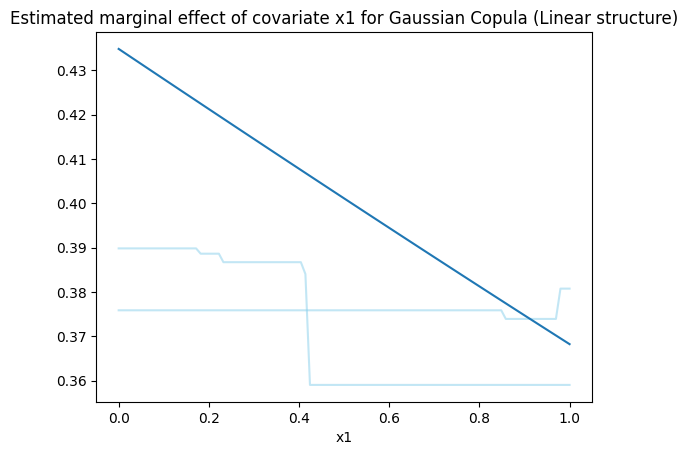

In [35]:
for i in range(n_sim):
    plt.plot(np.linspace(0,1, grid_resolution), results["linear"]["gaussian"]["pdp"]["x1"][i], alpha = 0.5, color="skyblue")
    
plt.plot(np.linspace(0,1, grid_resolution), truth_linear_x1, alpha = 1)
plt.title("Estimated marginal effect of covariate x1 for Gaussian Copula (Linear structure)")
plt.xlabel("x1")
plt.show()

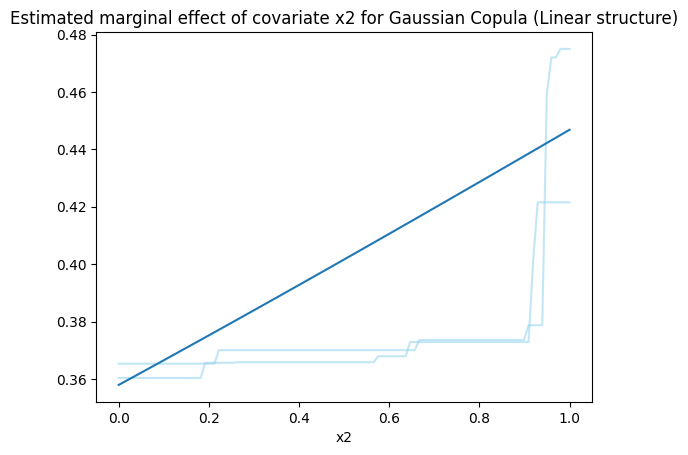

In [36]:
for i in range(n_sim):
    plt.plot(np.linspace(0,1, grid_resolution), results["linear"]["gaussian"]["pdp"]["x2"][i], alpha = 0.5, color="skyblue")
    
plt.plot(np.linspace(0,1, grid_resolution), truth_linear_x2, alpha = 1)
plt.title("Estimated marginal effect of covariate x2 for Gaussian Copula (Linear structure)")
plt.xlabel("x2")
plt.show()

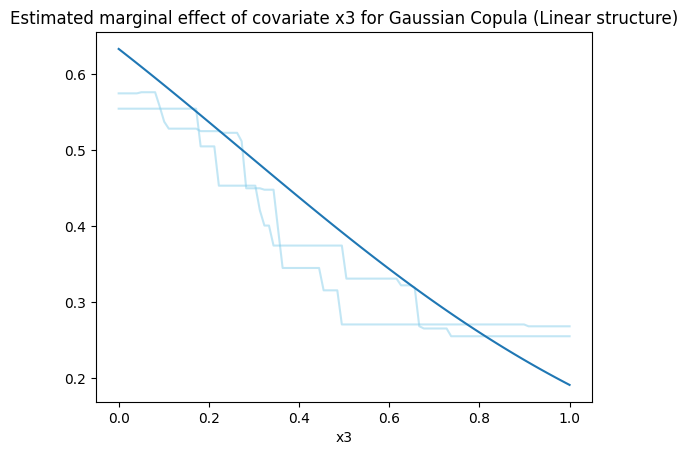

In [37]:
for i in range(n_sim):
    plt.plot(np.linspace(0,1, grid_resolution), results["linear"]["gaussian"]["pdp"]["x3"][i], alpha = 0.5, color="skyblue")
    
plt.plot(np.linspace(0,1, grid_resolution), truth_linear_x3, alpha = 1)
plt.title("Estimated marginal effect of covariate x3 for Gaussian Copula (Linear structure)")
plt.xlabel("x3")
plt.show()

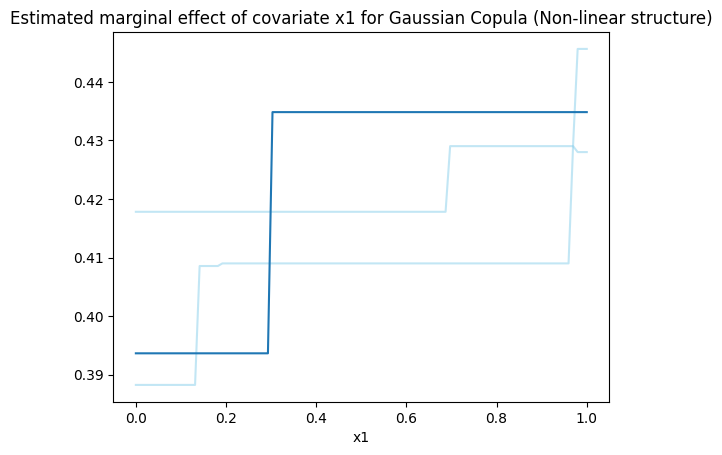

In [38]:
for i in range(n_sim):
    plt.plot(np.linspace(0,1, grid_resolution), results["non-linear"]["gaussian"]["pdp"]["x1"][i], alpha = 0.5, color="skyblue")
    
plt.plot(np.linspace(0,1, grid_resolution), truth_nonlinear_x1, alpha = 1)
plt.title("Estimated marginal effect of covariate x1 for Gaussian Copula (Non-linear structure)")
plt.xlabel("x1")
plt.show()

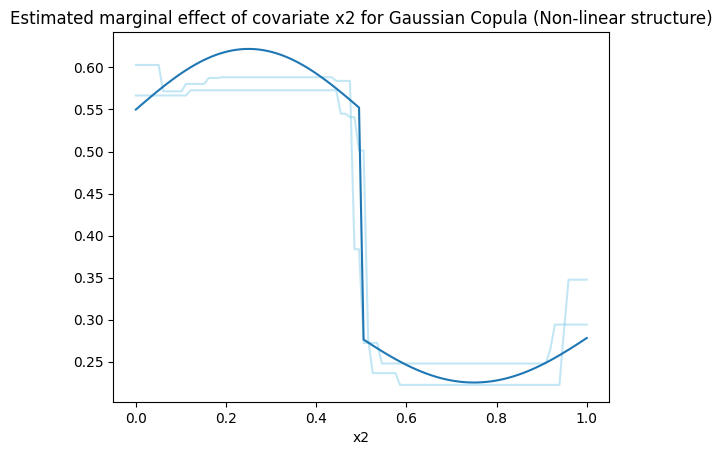

In [39]:
for i in range(n_sim):
    plt.plot(np.linspace(0,1, grid_resolution), results["non-linear"]["gaussian"]["pdp"]["x2"][i], alpha = 0.5, color="skyblue")
    
plt.plot(np.linspace(0,1, grid_resolution), truth_nonlinear_x2, alpha = 1)
plt.title("Estimated marginal effect of covariate x2 for Gaussian Copula (Non-linear structure)")
plt.xlabel("x2")
plt.show()

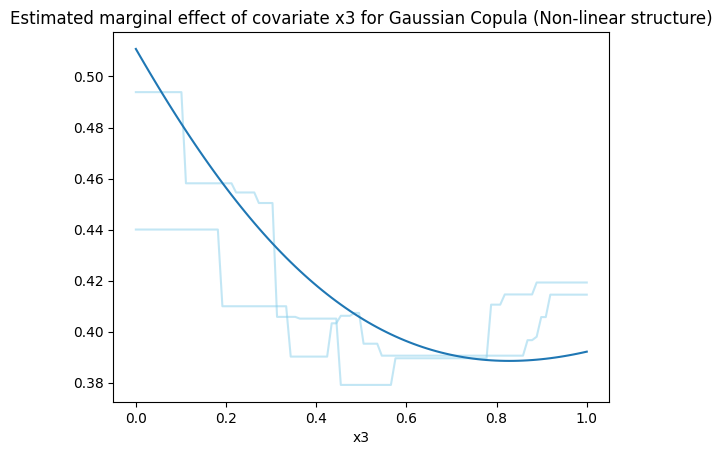

In [41]:
for i in range(n_sim):
    plt.plot(np.linspace(0,1, grid_resolution), results["non-linear"]["gaussian"]["pdp"]["x3"][i], alpha = 0.5, color="skyblue")
    
plt.plot(np.linspace(0,1, grid_resolution), truth_nonlinear_x3, alpha = 1)
plt.title("Estimated marginal effect of covariate x3 for Gaussian Copula (Non-linear structure)")
plt.xlabel("x3")
plt.show()

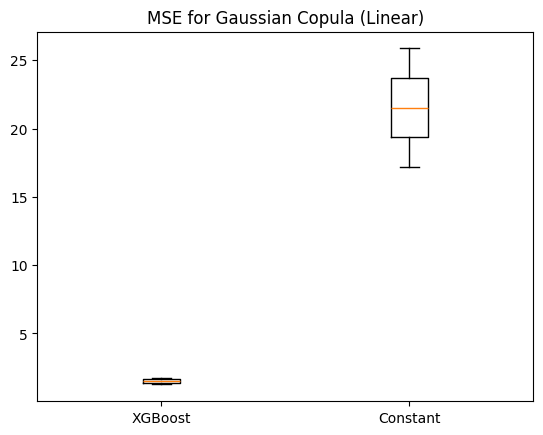

In [42]:
plt.boxplot([results["linear"]["gaussian"]["mse_xgb"], results["linear"]["gaussian"]["mse_constant"]], tick_labels=["XGBoost", "Constant"])
plt.title("MSE for Gaussian Copula (Linear)")
plt.show()

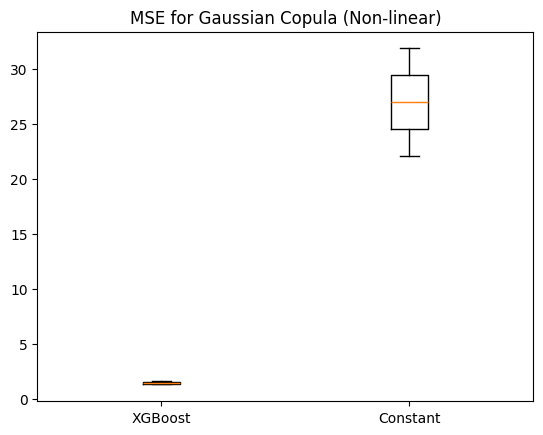

In [43]:
plt.boxplot([results["non-linear"]["gaussian"]["mse_xgb"], results["non-linear"]["gaussian"]["mse_constant"]], tick_labels=["XGBoost", "Constant"])
plt.title("MSE for Gaussian Copula (Non-linear)")
plt.show()

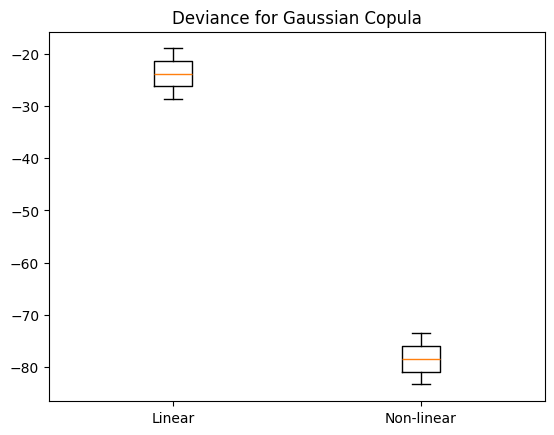

In [45]:
plt.boxplot([-2*(-np.array(results["linear"]["gaussian"]["nll_xgb"])+np.array(results["linear"]["gaussian"]["nll_constant"])), -2*(-np.array(results["non-linear"]["gaussian"]["nll_xgb"])+np.array(results["non-linear"]["gaussian"]["nll_constant"]))], tick_labels=["Linear", "Non-linear"])
plt.title("Deviance for Gaussian Copula")
plt.show()